<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
df = pd.read_csv("credit_risk_assessment_500_samples.csv")   # change path if needed
X = df.drop(columns=["Applicant_ID", "Credit_Risk"])
y = df["Credit_Risk"]


In [ ]:
df.head()

,Applicant_ID,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Loan_Term_Months,Existing_Loans_Count,Debt_to_Income_Ratio,Late_Payments_Last_2Yrs,Credit_Risk
0,1,59,153267,28,818,196649,12,2,0.68,0,High
1,2,49,232745,0,436,175354,60,0,0.23,5,High
2,3,35,974945,19,797,662297,48,3,0.54,0,Medium
3,4,63,307164,29,776,831725,48,0,0.56,4,High
4,5,28,685626,6,893,498625,60,3,0.66,8,High


In [ ]:
df.shape

(500, 11)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5,
                                            class_weight="balanced", random_state=42),
}

In [ ]:
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_test, pred, average="macro"),
        "F1-Score":  f1_score(y_test, pred, average="macro"),
        "CV F1 (5-fold)": cross_val_score(model, X, y, cv=5, scoring="f1_macro").mean(),
    }
    print(f"\n{name} confusion matrix (rows=actual, cols=predicted; Low/Medium/High):")
    print(confusion_matrix(y_test, pred, labels=["Low", "Medium", "High"]))

results = pd.DataFrame(results).T.round(3)
print("\n", results)
results.to_csv("credit_results.csv")


Logistic Regression confusion matrix (rows=actual, cols=predicted; Low/Medium/High):
[[ 4  0  0]
 [ 4 24  5]
 [ 0 12 51]]

Random Forest confusion matrix (rows=actual, cols=predicted; Low/Medium/High):
[[ 3  1  0]
 [ 0 33  0]
 [ 0  0 63]]

                      Accuracy  Precision  Recall  F1-Score  CV F1 (5-fold)
Logistic Regression      0.79      0.692   0.846     0.740           0.727
Random Forest            0.99      0.990   0.917     0.947           0.967


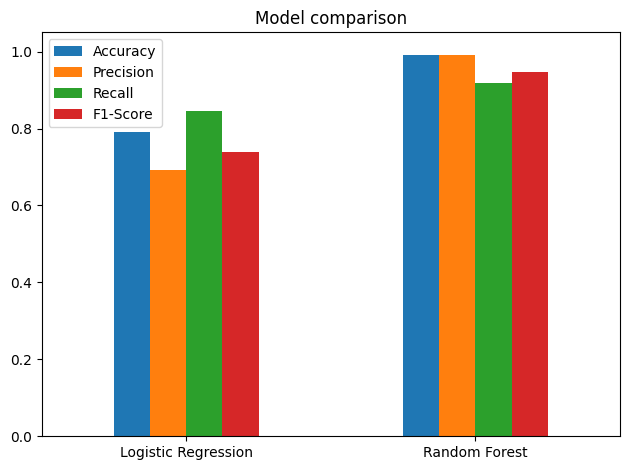

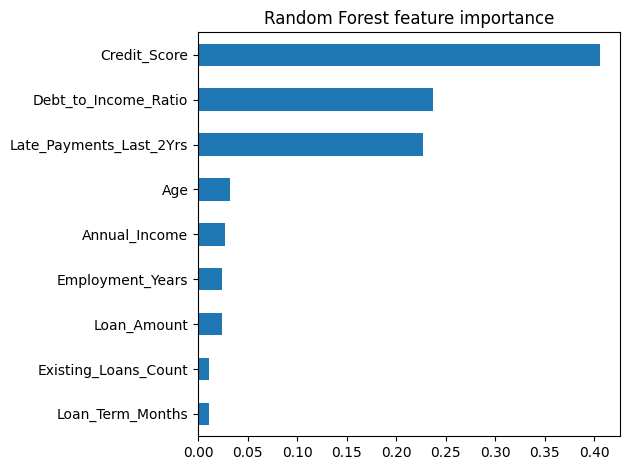

In [ ]:
results.drop(columns="CV F1 (5-fold)").plot(kind="bar", ylim=(0, 1.05), rot=0)
plt.title("Model comparison"); plt.tight_layout(); plt.savefig("credit_comparison.png", dpi=150)

plt.figure()
pd.Series(models["Random Forest"].feature_importances_, X.columns).sort_values().plot(kind="barh")
plt.title("Random Forest feature importance"); plt.tight_layout()
plt.savefig("credit_importance.png", dpi=150)